##  import libraies

In [77]:
import pandas as pd
import seaborn as sns
from sklearn.ensemble import AdaBoostClassifier,GradientBoostingClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
import xgboost as xgb
import lightgbm as lgb
from sklearn.metrics import accuracy_score,precision_score,recall_score,confusion_matrix
import warnings
warnings.filterwarnings("ignore")

# import data

In [7]:
credict_card_data=pd.read_csv("credit_card_clean.csv")
credict_card_data

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,1,20000.0,female,university,married,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,female,university,single,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,female,university,single,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,female,university,married,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,male,university,married,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,29996,220000.0,male,highschool,married,39,0,0,0,0,...,88004.0,31237.0,15980.0,8500.0,20000.0,5003.0,3047.0,5000.0,1000.0,0
29996,29997,150000.0,male,highschool,single,43,-1,-1,-1,-1,...,8979.0,5190.0,0.0,1837.0,3526.0,8998.0,129.0,0.0,0.0,0
29997,29998,30000.0,male,university,single,37,4,3,2,-1,...,20878.0,20582.0,19357.0,0.0,0.0,22000.0,4200.0,2000.0,3100.0,1
29998,29999,80000.0,male,highschool,married,41,1,-1,0,0,...,52774.0,11855.0,48944.0,85900.0,3409.0,1178.0,1926.0,52964.0,1804.0,1


In [ ]:
credict_card_data.

# data understanding

In [8]:
credict_card_data.isna().sum()

ID           0
LIMIT_BAL    0
SEX          0
EDUCATION    0
MARRIAGE     0
AGE          0
PAY_1        0
PAY_2        0
PAY_3        0
PAY_4        0
PAY_5        0
PAY_6        0
BILL_AMT1    0
BILL_AMT2    0
BILL_AMT3    0
BILL_AMT4    0
BILL_AMT5    0
BILL_AMT6    0
PAY_AMT1     0
PAY_AMT2     0
PAY_AMT3     0
PAY_AMT4     0
PAY_AMT5     0
PAY_AMT6     0
DEFAULT      0
dtype: int64

In [9]:
credict_card_data.dtypes

ID             int64
LIMIT_BAL    float64
SEX           object
EDUCATION     object
MARRIAGE      object
AGE            int64
PAY_1          int64
PAY_2          int64
PAY_3          int64
PAY_4          int64
PAY_5          int64
PAY_6          int64
BILL_AMT1    float64
BILL_AMT2    float64
BILL_AMT3    float64
BILL_AMT4    float64
BILL_AMT5    float64
BILL_AMT6    float64
PAY_AMT1     float64
PAY_AMT2     float64
PAY_AMT3     float64
PAY_AMT4     float64
PAY_AMT5     float64
PAY_AMT6     float64
DEFAULT        int64
dtype: object

In [10]:
credict_card_data.describe()

,ID,LIMIT_BAL,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,-0.266200,-0.291100,51223.330900,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,9.217904,1.123802,1.197186,1.196868,1.169139,1.133187,1.149988,73635.860576,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,-165580.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,3558.750000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,34.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,22381.500000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,41.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,67091.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,79.000000,8.000000,8.000000,8.000000,8.000000,8.000000,8.000000,964511.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


In [13]:
credict_card_data.shape

(30000, 25)

# Data preparations

In [17]:
lable_encoder = LabelEncoder()
credict_card_data["SEX"]=lable_encoder.fit_transform(credict_card_data["SEX"])
credict_card_data["EDUCATION"]=lable_encoder.fit_transform(credict_card_data["EDUCATION"])
credict_card_data["MARRIAGE"]=lable_encoder.fit_transform(credict_card_data["MARRIAGE"])

In [18]:
del credict_card_data["ID"]

In [21]:
X=credict_card_data.drop(labels="DEFAULT",axis=1)
y=credict_card_data["DEFAULT"]

In [98]:
X_train,X_test,y_train,y_test=train_test_split(X,y,train_size=0.75,random_state=182,shuffle=True,stratify=y)

In [92]:
X_train.shape,y_train.shape

((22500, 23), (22500,))

In [93]:
X_test.shape,y_test.shape

((7500, 23), (7500,))

# model building

In [110]:
ab_classifiers  = AdaBoostClassifier()
gb_classifiers   = GradientBoostingClassifier()
xgb_classifiers  = xgb.XGBClassifier()
lgb_classifiers  = lgb.LGBMClassifier()

# model Training 

## aadaa_bosting_algorithum

# training data

In [112]:
%%time
ab_classifiers  = AdaBoostClassifier()
ab_classifiers.fit(X_train,y_train)
Y_pred_train_ab=ab_classifiers.predict(X_train)
print("accuracy_score:",round(accuracy_score(y_train,Y_pred_train_ab),2))
print("precision_score",round(precision_score(y_train,Y_pred_train_ab),2))
print("recall_score:",round(recall_score(y_train,Y_pred_train_ab),2))
print("confusion matrix:\n",confusion_matrix(y_train,Y_pred_train_ab))

accuracy_score: 0.82
precision_score 0.7
recall_score: 0.33
confusion matrix:
 [[16810   713]
 [ 3327  1650]]
CPU times: total: 4.33 s
Wall time: 4.52 s


## gradiant_boosting_algorithum

In [117]:
%%time
gb_classifiers  = GradientBoostingClassifier()
gb_classifiers.fit(X_train,y_train)
Y_pred_train_gb=gb_classifiers.predict(X_train)
print("accuracy_score:",round(accuracy_score(y_train,Y_pred_train_gb),2))
print("precision_score",round(precision_score(y_train,Y_pred_train_gb),2))
print("recall_score:",round(recall_score(y_train,Y_pred_train_gb),2))
print("confusion matrix:\n",confusion_matrix(y_train,Y_pred_train_gb))

accuracy_score: 0.83
precision_score 0.71
recall_score: 0.38
confusion matrix:
 [[16746   777]
 [ 3086  1891]]
CPU times: total: 21.1 s
Wall time: 21.5 s


# Extreme gradient_boosting_algorithum

In [122]:
%%time
xgb_classifiers  =xgb.XGBClassifier()
xgb_classifiers.fit(X_train,y_train)
Y_pred_train_xgb=xgb_classifiers.predict(X_train)
print("accuracy_score:",round(accuracy_score(y_train,Y_pred_train_xgb),2))
print("precision_score",round(precision_score(y_train,Y_pred_train_xgb),2))
print("recall_score:",round(recall_score(y_train,Y_pred_train_xgb),2))
print("confusion matrix:\n",confusion_matrix(y_train,Y_pred_train_xgb))

accuracy_score: 0.89
precision_score 0.9
recall_score: 0.58
confusion matrix:
 [[17189   334]
 [ 2072  2905]]
CPU times: total: 2.48 s
Wall time: 424 ms


# Light_gradiants_boosting_algorithums

In [126]:
%%time
lgb_classifiers  = lgb.LGBMClassifier()
lgb_classifiers.fit(X_train,y_train)
Y_pred_train_lgb=lgb_classifiers.predict(X_train)
print("accuracy_score:",round(accuracy_score(y_train,Y_pred_train_lgb),2))
print("precision_score",round(precision_score(y_train,Y_pred_train_lgb),2))
print("recall_score:",round(recall_score(y_train,Y_pred_train_lgb),2))
print("confusion matrix:\n",confusion_matrix(y_train,Y_pred_train_lgb))

[LightGBM] [Info] Number of positive: 4977, number of negative: 17523
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.005595 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3260
[LightGBM] [Info] Number of data points in the train set: 22500, number of used features: 23
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.221200 -> initscore=-1.258687
[LightGBM] [Info] Start training from score -1.258687
accuracy_score: 0.84
precision_score 0.77
recall_score: 0.42
confusion matrix:
 [[16901   622]
 [ 2879  2098]]
CPU times: total: 2.59 s
Wall time: 430 ms


# *** the end ***

# Fetures importances

In [130]:
adab_features_impo = ab_classifiers.feature_importances_
gb_features_impo   = gb_classifiers.feature_importances_
xgb_features_impo  = xgb_classifiers.feature_importances_
lgb_features_impo  = lgb_classifiers.feature_importances_

In [142]:
important_features=pd.DataFrame(data=  {"features_names":columns_name,
                     "Aadaboosting_features":adab_features_impo,
                     "gdb_features":gb_features_impo,
                     "xgb_features":xgb_features_impo,
                     "lgb_features_impo":lgb_features_impo})
important_features

,features_names,Aadaboosting_features,gdb_features,xgb_features,lgb_features_impo
0,LIMIT_BAL,0.035078,0.024427,0.022404,234
1,SEX,0.000000,0.001441,0.017913,38
2,EDUCATION,0.000000,0.001750,0.020553,46
3,MARRIAGE,0.017011,0.002604,0.014940,36
4,AGE,0.000000,0.009728,0.017977,200
5,PAY_1,0.560285,0.640324,0.391905,76
6,PAY_2,0.000000,0.069168,0.094738,44
7,PAY_3,0.063530,0.044819,0.077098,48
8,PAY_4,0.000000,0.016814,0.039038,42
9,PAY_5,0.000000,0.011455,0.031266,29


<Axes: xlabel='Aadaboosting_features', ylabel='features_names'>

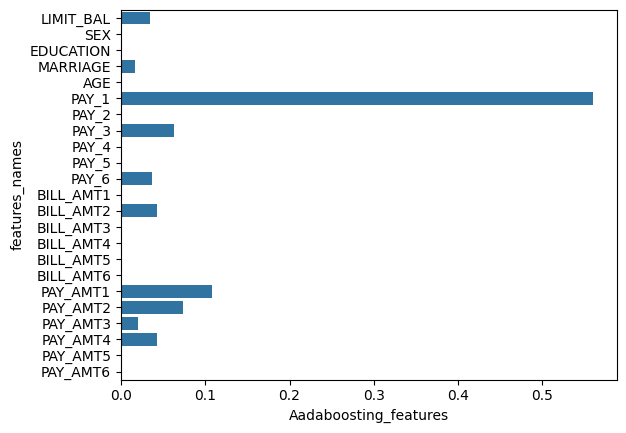

In [144]:
sns.barplot(data=important_features,x="Aadaboosting_features",y="features_names")